In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("heliosli/rsna-knee-r6-frozen-fe055406")

print("Path to dataset files:", path)

KaggleApiHTTPError: 403 Client Error.

You don't have permission to access resource at URL: https://api.kaggle.com/v1/datasets.DatasetApiService/GetDataset. Please make sure you are authenticated if you are trying to access a private resource or a resource requiring consent.

In [1]:
import pandas as pd

splits = {'train': 'data/train-00000-of-00001-c08a401c53fe5312.parquet', 'test': 'data/test-00000-of-00001-44110b9df98c5585.parquet'}
df_train = pd.read_parquet("hf://datasets/Falah/Alzheimer_MRI/" + splits["train"])
df_test = pd.read_parquet("hf://datasets/Falah/Alzheimer_MRI/" + splits["test"])

'timed out' thrown while requesting GET https://huggingface.co/datasets/Falah/Alzheimer_MRI/resolve/main/data/test-00000-of-00001-44110b9df98c5585.parquet
Retrying in 1s [Retry 1/5].
'timed out' thrown while requesting GET https://huggingface.co/datasets/Falah/Alzheimer_MRI/resolve/main/data/test-00000-of-00001-44110b9df98c5585.parquet
Retrying in 2s [Retry 2/5].
'[SSL: UNEXPECTED_EOF_WHILE_READING] EOF occurred in violation of protocol (_ssl.c:1028)' thrown while requesting GET https://huggingface.co/datasets/Falah/Alzheimer_MRI/resolve/main/data/test-00000-of-00001-44110b9df98c5585.parquet
Retrying in 4s [Retry 3/5].


In [17]:
import io
import matplotlib.pyplot as plt
from PIL import Image

img = Image.open(io.BytesIO(df_train.iloc[0]["image"]["bytes"]))
plt.imshow(img, cmap="gray")

IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices

In [4]:
import numpy as np
from PIL import Image
import io

def decode(item, size=(128, 128)):
    img = Image.open(io.BytesIO(item["bytes"])).convert("RGB")
    img = img.resize(size)
    return np.asarray(img, dtype="float32") / 255.0


In [5]:
df_train['image'] = df_train['image'].apply(decode)
df_test['image'] = df_test['image'].apply(decode)


In [6]:
from sklearn.model_selection import train_test_split

In [7]:
X_train = np.stack(df_train["image"]).astype("float32")
Y_train = df_train['label']


X_test = np.stack(df_test["image"]).astype("float32")
Y_test = df_test['label']

In [8]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models

In [ ]:
seq = keras.Sequential([
    layers.Conv2D(32 , (3,3), activation='relu' , input_shape=(128,128,3)),
    layers.MaxPooling2D((2,2)),
    
    layers.Conv2D(64,(3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    
    layers.Conv2D(128,(4,4), activation= 'relu'),
    layers.MaxPooling2D((2,2)),
    
    layers.Conv2D(128,(4,4), activation= 'relu'),
    layers.MaxPooling2D((2,2)),
    
    layers.Flatten(),
    layers.Dense(512, activation='relu'),
    layers.Dense(128, activation='relu'),
    layers.Dense(512, activation='relu'),
    layers.Dense(1, activation='sigmoid') #softmax get more than 1 from y uniq
    
])

c:\Users\r.navabian\AppData\Local\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
seq.compile(optimizer='rmsprop', loss='binary_crossentropy', metrics=['accuracy'])

In [45]:
seq.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 27, 27, 128)    │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 13, 13, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 10, 10, 128)    │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 5, 5, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 3200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 512)            │     1,638,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,150,721 (8.20 MB)

 Trainable params: 2,150,721 (8.20 MB)

 Non-trainable params: 0 (0.00 B)

In [46]:
import numpy as np

In [47]:
hist = seq.fit(X_train, Y_train, epochs=5, batch_size=32,validation_split= 0.2)

Epoch 1/5
128/128 ━━━━━━━━━━━━━━━━━━━━ 13s 97ms/step - accuracy: 0.0103 - loss: -2910895708176409165824.0000 - val_accuracy: 0.0068 - val_loss: -3789756568434135531520.0000
Epoch 2/5
128/128 ━━━━━━━━━━━━━━━━━━━━ 12s 93ms/step - accuracy: 0.0103 - loss: -4681242707297241661440.0000 - val_accuracy: 0.0068 - val_loss: -5971069418451501056000.0000
Epoch 3/5
128/128 ━━━━━━━━━━━━━━━━━━━━ 12s 93ms/step - accuracy: 0.0103 - loss: -7223455735578592542720.0000 - val_accuracy: 0.0068 - val_loss: -9097071400054937354240.0000
Epoch 4/5
128/128 ━━━━━━━━━━━━━━━━━━━━ 12s 94ms/step - accuracy: 0.0103 - loss: -10892961127412355039232.0000 - val_accuracy: 0.0068 - val_loss: -13603990743300758831104.0000
Epoch 5/5
128/128 ━━━━━━━━━━━━━━━━━━━━ 12s 96ms/step - accuracy: 0.0103 - loss: -16093631282806976937984.0000 - val_accuracy: 0.0068 - val_loss: -19813579805217056096256.0000


In [48]:
import matplotlib.pylab as plt

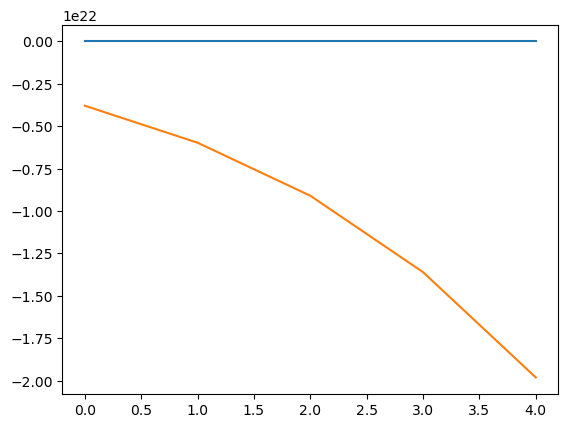

In [50]:
plt.plot(hist.history['val_accuracy'])
plt.plot(hist.history['val_loss'])

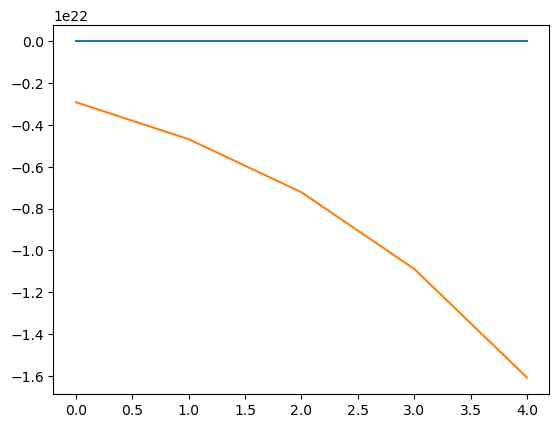

In [49]:
plt.plot(hist.history['accuracy'])
plt.plot(hist.history['loss'])